# Covariance decomposition and inference scenarios with TwINFER

This tutorial shows how to score a pair of genes with `infer_with_twinfer`, how to read the three z-scores and the inference scenario it reports, and how to draw the result as a network.

**What TwINFER uses.** Sister cells ("twins") come from the same mother cell. Right after division they share their molecules and the cell state they inherited; with time, each sister's expression drifts away from the other's. Because of this, the correlation of two genes across cells can be split into a part the twins share and a part that differs between twins. The two parts tell apart two reasons why two genes are correlated:

* **regulation**: X acts on Y in every cell, so the correlation shows up in the twin differences too;
* **heterogeneity**: cells sit in different states (for example two cell types) that set both genes. Twins sit in the same state, so the correlation is shared by twins and is absent from their differences.

**The three z-scores** (one gene pair, N twin pairs):

| z-score | measures | significant when |
|---|---|---|
| `z_rho` | the expression correlation of X and Y over all cells (Spearman) | \|z\| > 1.96 |
| `z_rho_s` | the twin-shared part: X in one sister against Y in the other sister | \|z\| > 2.326 |
| `z_rho_delta` | the correlation of the twin differences (X in sister 1 minus sister 2, the same for Y) | \|z\| > 1.96 |

All three are analytic (no shuffling) and use N = the number of twin pairs. When many gene pairs are scored at once (real data), `z_rho` and `z_rho_delta` are tested with a Benjamini-Hochberg correction instead of the fixed thresholds (section 7).

**The four inference scenarios** follow from these z-scores:

| scenario | z_rho | z_rho_s | z_rho_delta | reading |
|---|---|---|---|---|
| 1 nothing | not significant | | | no correlation |
| 2 regulation | significant | not significant | | correlation not shared by twins |
| 3 regulation + heterogeneity | significant | significant | significant | shared part and a twin-difference part |
| 4 heterogeneity | significant | significant | not significant | correlation only through a shared state |

**Data used here.** A simulated two-gene network in which gene 1 activates gene 2 (A → B), with 6,000 twin pairs followed for 48 hours after division. The file ships with the repository in `simulation_example_output_data/`.

## 1. Setup

Install the package once from the repository root (`pip install -e package/`, see the README). Then:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from twinfer.inference.covariance_decomposition_z_scores import (
    INFERENCE_SCENARIOS,
    classify_inference_scenario,
    infer_with_twinfer,
)
from twinfer.plotting.network_plots import network_from_scenarios, plot_grn
from twinfer.utils.paths import get_repo_root

data_file = get_repo_root() / "simulation_example_output_data" / "df_rows_0_0_20112025_222419_ncells_6000_A_to_B_4e702629.csv"

## 2. The input table

`infer_with_twinfer` reads a long table with one row per cell and time point:

* `clone_id`: the twin pair (the mother cell);
* `replicate`: 1 or 2, which sister;
* `time_step`: hours after division;
* one column per measured quantity (here mRNA and protein counts of the two genes).

In [2]:
table = pd.read_csv(data_file)
print(f"{table['clone_id'].nunique()} twin pairs, time steps {table['time_step'].min()}-{table['time_step'].max()} h")
table.head()

6000 twin pairs, time steps 0-48 h


,cell_id,time_step,gene_1_mRNA,gene_1_protein,gene_2_mRNA,gene_2_protein,replicate,clone_id
0,0,0,0,15158,3,35482,1,0
1,0,1,0,14937,2,36274,1,0
2,0,2,0,14723,4,37046,1,0
3,0,3,0,14490,4,38719,1,0
4,0,4,1,14483,4,40448,1,0


## 3. Score the gene pair at one time point

We use the mRNA counts 20 hours after division. With one time point in `time_points`, the function compares the two sisters of every twin pair at that time.

In [3]:
genes = ["gene_1_mRNA", "gene_2_mRNA"]
result = infer_with_twinfer(table, genes, time_points=[20])
result[["gene_x", "gene_y", "N", "z_rho", "z_rho_s", "z_rho_delta", "inference_scenario"]]

,gene_x,gene_y,N,z_rho,z_rho_s,z_rho_delta,inference_scenario
0,gene_1_mRNA,gene_2_mRNA,6000,7.216797,0.707215,4.969163,2


`z_rho` and `z_rho_delta` are significant, `z_rho_s` is not. The pair is called scenario 2, regulation:

* `z_rho` is large: the two genes are correlated;
* `z_rho_s` (0.7) is below 2.326: what sister 1 expresses of gene 1 tells little about what sister 2 expresses of gene 2, so the correlation is not carried by a shared state;
* `z_rho_delta` is large: when one sister has more gene 1 than its twin, it also has more gene 2. Regulation acts inside each cell.

The table holds the quantities the z-scores are built from. `S` is the Spearman correlation over all cells. `C` is its twin-shared part and `U = S - C` the unshared part. `h_x`, `h_y` are the sister correlations of each gene (how alike the twins are). `z_rho` splits exactly into a shared and an unshared contribution, `z_rho = A_s + A_u`:

In [4]:
row = result.iloc[0]
print(f"S = {row.S:.4f} = C + U = {row.C:.4f} + {row.U:.4f}")
print(f"z_rho = {row.z_rho:.3f} = A_s + A_u = {row.A_s:.3f} + {row.A_u:.3f}")
print(f"sister correlations: h_x = {row.h_x:.3f}, h_y = {row.h_y:.3f}")

S = 0.0659 = C + U = 0.0065 + 0.0595
z_rho = 7.217 = A_s + A_u = 0.709 + 6.508
sister correlations: h_x = 0.015, h_y = 0.128


The scenario can also be computed from any three z-scores with `classify_inference_scenario` (thresholds can be changed with `thresholds=(z_rho, z_rho_s, z_rho_delta)`):

In [5]:
scenario = classify_inference_scenario(row.z_rho, row.z_rho_s, row.z_rho_delta)[0]
print(scenario, INFERENCE_SCENARIOS[scenario])

2 regulation


## 4. When to measure: time after division

Right after division the twins have just split their mother's molecules, so they are almost identical (high `h`). Any correlation then looks shared, and the twin differences are too small to show regulation. As the sisters drift apart, the twin difference becomes informative. Scoring every time step shows this:

In [6]:
over_time = pd.concat(
    [infer_with_twinfer(table, genes, time_points=[t]) for t in sorted(table["time_step"].unique()) if t > 0],
    ignore_index=True,
)
over_time[["t_a", "z_rho", "z_rho_s", "z_rho_delta", "h_x", "h_y", "inference_scenario"]].iloc[[0, 1, 4, 9, 19, 47]]

,t_a,z_rho,z_rho_s,z_rho_delta,h_x,h_y,inference_scenario
0,1,4.288861,4.834040,-1.774503,0.700967,0.755323,4
1,2,4.970090,4.903048,0.107233,0.484853,0.583734,4
4,5,6.763568,2.791675,3.698860,0.159239,0.285055,3
9,10,6.964390,2.175207,3.912930,0.028934,0.225071,2
19,20,7.216797,0.707215,4.969163,0.014945,0.127686,2
47,48,4.861631,0.846377,2.889465,0.009622,0.025268,2


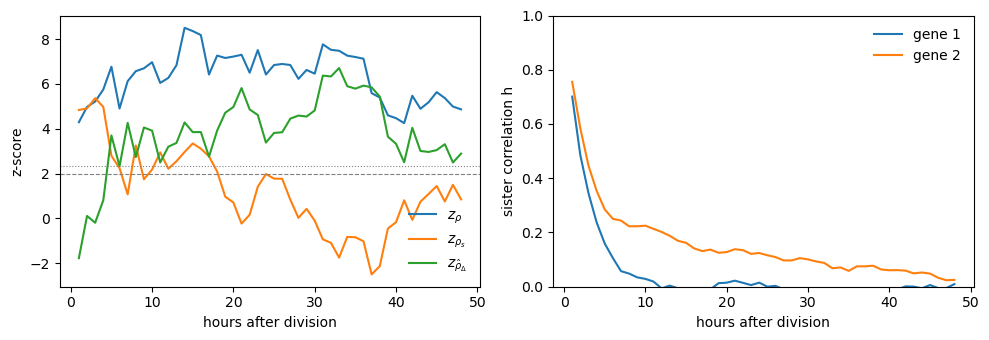

In [7]:
fig, (ax_z, ax_h) = plt.subplots(1, 2, figsize=(10, 3.5))
for column, label in [("z_rho", "$z_\\rho$"), ("z_rho_s", "$z_{\\rho_s}$"), ("z_rho_delta", "$z_{\\hat\\rho_\\Delta}$")]:
    ax_z.plot(over_time["t_a"], over_time[column], label=label)
ax_z.axhline(1.96, color="grey", linestyle="--", linewidth=0.8)
ax_z.axhline(2.326, color="grey", linestyle=":", linewidth=0.8)
ax_z.set(xlabel="hours after division", ylabel="z-score")
ax_z.legend(frameon=False)
ax_h.plot(over_time["t_a"], over_time["h_x"], label="gene 1")
ax_h.plot(over_time["t_a"], over_time["h_y"], label="gene 2")
ax_h.set(xlabel="hours after division", ylabel="sister correlation h", ylim=(0, 1))
ax_h.legend(frameon=False)
fig.tight_layout()

In [8]:
over_time.groupby("inference_scenario", observed=True)["t_a"].agg(["min", "max", "count"])

,min,max,count
inference_scenario,,,
2,6,48,35
3,5,37,9
4,1,4,4


In the first four hours the pair is called scenario 4 (heterogeneity) although the network has no second state: the twins still share their inherited mRNA (h around 0.5-0.75), so the correlation looks shared and the twin differences carry no signal. Between 5 and 17 hours the sisters drift apart and `z_rho_s` hovers around its threshold, so the call alternates between scenario 3 and scenario 2. From 18 hours on the pair is called scenario 2 at every time point except one (37 hours, where `z_rho_s` is just above the threshold). The simulations in the paper are scored at 20 hours.

## 5. How many twin pairs are needed

For a fixed correlation, the z-scores grow with the square root of the number of twin pairs. Scoring one random subset of clones per size at 20 hours:

In [9]:
rng = np.random.default_rng(0)
clones = table["clone_id"].unique()
rows = []
for n in [100, 250, 500, 1000, 3000, 6000]:
    chosen = rng.choice(clones, size=n, replace=False)
    rows.append(infer_with_twinfer(table[table["clone_id"].isin(chosen)], genes, time_points=[20]))
pd.concat(rows)[["N", "z_rho", "z_rho_s", "z_rho_delta", "inference_scenario"]]

,N,z_rho,z_rho_s,z_rho_delta,inference_scenario
0,100,2.132603,-0.050308,1.805744,2
0,250,0.957914,-1.731536,1.850387,1
0,500,1.967992,1.000107,0.774551,2
0,1000,2.331536,0.196850,1.552705,2
0,3000,5.452194,1.145131,3.263425,2
0,6000,7.216797,0.707215,4.969163,2


The correlation in this example is weak (Spearman 0.07 at 20 hours), so with fewer than about 1,000 twin pairs it is not reliably detected; each subset is a single random draw, so the small sizes scatter.

## 6. Direction from two time points

With two time points, `infer_with_twinfer` splits the clones at random (fixed `seed`; proportions `split`, default 1:1:2) into twin pairs measured at the first time, twin pairs measured at the second time, and a cross group in which one sister is measured at the first time and the other sister at the second time. In the cross group:

* `rho_dag_xy` = correlation of gene X in one sister at the first time with gene Y in the other sister at the second time (and `rho_dag_yx` the other way round), `z_dag = rho_dag * sqrt(N_cross - 1)`;
* if X regulates Y, X earlier predicts Y later better than Y earlier predicts X later: `delta = rho_dag_xy - rho_dag_yx > 0`;
* `p_delta` is a permutation p-value of `delta` (`n_permutations`, default 1,000).

The covariance z-scores and the scenario are reported for both twin groups (suffix `_ta` for the first time, `_tb` for the second).

In [10]:
two_times = infer_with_twinfer(table, genes, time_points=[1, 20])
two_times[["gene_x", "gene_y", "N_a", "N_b", "N_cross", "z_dag_xy", "z_dag_yx", "delta", "p_delta", "inference_scenario_ta", "inference_scenario_tb"]]

,gene_x,gene_y,N_a,N_b,N_cross,z_dag_xy,z_dag_yx,delta,p_delta,inference_scenario_ta,inference_scenario_tb
0,gene_1_mRNA,gene_2_mRNA,1500,1500,3000,8.257721,0.168798,0.147707,0.000999,4,2


`z_dag_xy` is large and `z_dag_yx` is close to 0: gene 1 at 1 hour predicts gene 2 at 20 hours, not the reverse, so the direction gene 1 → gene 2 is recovered (`p_delta` is at its minimum, 1/1001).

## 7. Real data: clones of any size

Lineage-tracing experiments give clone labels instead of exact sister pairs: a clone can have one cell (singleton), two, or more. For this, pass one row per cell with `clone_id` and the genes, and **no** `replicate` column; the function then uses the `"clones"` scenario. Every within-clone cell pair is used, each clone has weight 1, and singletons enter the expression correlation `z_rho`.

Real data score many gene pairs at once, so two z-scores are then tested with a **Benjamini-Hochberg correction** of their two-sided p-values: `z_rho` over all pairs scored (significant when `q_rho` ≤ 0.05), and `z_rho_delta` over the pairs whose `z_rho` is significant (significant when `q_rho_delta` ≤ 0.05). `z_rho_s` keeps its threshold. `correction="none"` uses the fixed thresholds instead; `correction="bh"` also corrects twin-pair tables; `fdr=` sets the level.

The values are used as given. For count data, normalise before calling (for example log1p of counts per 10,000); TwINFER's statistics are rank-based, but ranks of raw counts still depend on each cell's sequencing depth.

With clones of exactly two cells, the `"clones"` scenario reproduces the twin-pair z-scores (here a single gene pair, so each q-value equals its p-value):

In [11]:
cells = table.loc[table["time_step"] == 20, ["clone_id"] + genes]   # one row per cell, no replicate column
as_clones = infer_with_twinfer(cells, genes)
pd.concat([result.assign(input="twin pairs"), as_clones.assign(input="clones")])[["input", "z_rho", "z_rho_s", "z_rho_delta", "q_rho", "q_rho_delta", "inference_scenario"]]

,input,z_rho,z_rho_s,z_rho_delta,q_rho,q_rho_delta,inference_scenario
0,twin pairs,7.216797,0.707215,4.969163,NaN,NaN,2
0,clones,7.216797,0.707215,4.969163,5.322623e-13,6.724264e-07,2


Removing one sister from 2,000 clones turns them into singletons; the twin terms now come from the remaining 4,000 pairs:

In [12]:
drop = cells.drop_duplicates("clone_id").sample(2000, random_state=0).index
with_singletons = infer_with_twinfer(cells.drop(drop), genes)
with_singletons[["z_rho", "z_rho_s", "z_rho_delta", "q_rho", "q_rho_delta", "inference_scenario"]]

,z_rho,z_rho_s,z_rho_delta,q_rho,q_rho_delta,inference_scenario
0,6.084279,0.526673,4.423911,1.170166e-09,0.00001,2


For many genes, pass `regulators=` and `targets=` (lists of gene names) to score only regulator × target pairs; the computation runs in blocks (`chunk_x`, `chunk_y`).

## 8. Draw the result as a network

`network_from_scenarios` turns the result table into the inputs of `plot_grn`:

* scenario 2 or 3 (regulation): **solid** edge;
* scenario 4 (heterogeneity, a shared state): **dashed** edge without direction;
* scenario 1: no edge;
* a solid edge gets a direction only when the table has two time points and `p_delta < 0.05`; otherwise it is drawn without direction;
* colour and sign (arrow for positive, bar for negative) come from `z_rho`.

$g_1$ and $g_2$ below are gene 1 and gene 2.

With two time points, `time="tb"` (default) uses the scenario at the later time.

1 h after division
     source      target   weight  inference_scenario line_style  directed
gene_1_mRNA gene_2_mRNA 2.019378                   4         --     False

20 h after division
     source      target   weight  inference_scenario line_style  directed
gene_1_mRNA gene_2_mRNA 3.366897                   2      solid      True



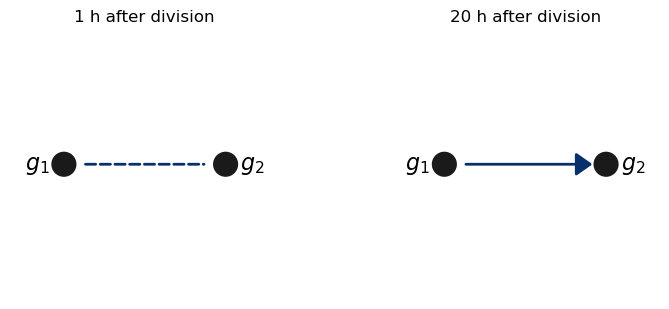

In [13]:
labels = {"gene_1_mRNA": "$g_1$", "gene_2_mRNA": "$g_2$"}
positions = {0: (0.2, 0.5), 1: (0.8, 0.5)}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, time, title in [(axes[0], "ta", "1 h after division"), (axes[1], "tb", "20 h after division")]:
    plot_kwargs, edges = network_from_scenarios(two_times, time=time)
    plot_kwargs["node_labels"] = [labels[g] for g in plot_kwargs["node_labels"]]
    plot_grn(**plot_kwargs, ax=ax, fixed_pos=positions, show_colorbar=False, figsize=(8, 8))   # figsize sets line and arrow scale
    ax.set_title(title)
    print(title)
    print(edges.to_string(index=False), end="\n\n")

At 1 hour the pair is called heterogeneity (dashed: the twins still share their inherited mRNA); at 20 hours it is regulation, with the direction from the cross-time correlation (gene 1 → gene 2). The same two calls work for any number of genes: pass all gene columns to `infer_with_twinfer` and the whole result table to `network_from_scenarios`. `plot_grn(**plot_kwargs)` draws the nodes on a circle when `fixed_pos` is not given.

## Summary

| step | call |
|---|---|
| score gene pairs at one time point | `infer_with_twinfer(table, genes, time_points=[t])` |
| add the direction | `infer_with_twinfer(table, genes, time_points=[t_a, t_b])` |
| real data with clone labels | `infer_with_twinfer(cells, genes)` (no `replicate` column; optionally `regulators=`, `targets=`) |
| scenario from z-scores | `classify_inference_scenario(z_rho, z_rho_s, z_rho_delta)` (`correction="bh"` for many pairs) |
| network figure | `plot_grn(**network_from_scenarios(result)[0])` |

The analyses of the paper that use these functions are in `paper_analysis/` (for example `heterogeneity_vs_regulation/` scores single-state, two-state and drifting simulations the same way).